Ce notebook presente le modele SVM regression pour la variable cible 'TousAge_allergie_urgences'

In [1]:
import pandas as pd
import numpy as np

Merge_final = pd.read_csv("../data/final_metropole/Merge_final_2.csv")

Merge_final.info()

Merge_final.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 81 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

C:\Users\gauxm\AppData\Local\Temp\ipykernel_6632\2492055701.py:4: DtypeWarning: Columns (1: code_dept) have mixed types. Specify dtype option on import or set low_memory=False.
  Merge_final = pd.read_csv("../data/final_metropole/Merge_final_2.csv")


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


In [2]:
#Suppression colonnes
Merge_final_FS_MLA = Merge_final.drop(columns=[
    '0an_bronchiolite_urgences', 
    '65plus_allergie_urgences',
    '0_14_allergie_urgences',
    '15_64_allergie_urgences',
    '0_14_asthme_urgences',
    '15_64_asthme_urgences',
    'TousAge_asthme_urgences',
    '65plus_asthme_urgences',
    '0an_bronchiolite_hospitalisation',
    'TousAge_allergie_hospitalisation',
    '65plus_allergie_hospitalisation',
    '0_14_allergie_hospitalisation',
    '15_64_allergie_hospitalisation',
    '0_14_asthme_hospitalisation',
    '15_64_asthme_hospitalisation',
    'TousAge_asthme_hospitalisation',
    '65plus_asthme_hospitalisation',
    'Ntop_Maladie_Respi_Chronique_tsage_9',
    'Npop_Maladie_Respi_Chronique_tsage_9',
    'Ntop_Maladie_Respi_Chronique_0-14_9',
    'Ntop_Maladie_Respi_Chronique_15-64_9',
    'Ntop_Maladie_Respi_Chronique_65+_9',
    'Npop_Maladie_Respi_Chronique_0-14_9',
    'Npop_Maladie_Respi_Chronique_15-64_9',
    'Npop_Maladie_Respi_Chronique_65+_9',
    'nom_dep',])

Merge_final_FS_MLA.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 55 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

In [3]:
#Met dans le bon type les variables

Merge_final_FS_MLA["code_dept"] = Merge_final_FS_MLA["code_dept"].astype("str")

Merge_final_FS_MLA['sos_present'] = Merge_final_FS_MLA['sos_present'].astype(int)

Merge_final_FS_MLA.info()

Merge_final_FS_MLA.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 55 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0


Étape 1 : Préparation du DataFrame & Découpage Temporel

In [4]:
# Copie de travail depuis Merge_final_FS_MLA
df = Merge_final_FS_MLA.copy()

# Extraction de l'année
df['annee'] = (
    df['date_semaine'].astype(str).str[:4].astype(int)
)

# Split temporel strict
df_train = df[df['annee'] <= 2022]
df_val = df[df['annee'] == 2023]
df_test = df[df['annee'] == 2024]

df.info()

df_test.info()

df_test.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 56 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present,annee
156,2024-S01,01,0.667750,0.650833,0.086167,2.0555,0.003767,14.357143,42.928571,8.000000,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
157,2024-S02,01,0.509437,0.638333,0.061333,1.7920,0.002724,16.242857,22.714286,30.785714,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
158,2024-S03,01,0.741125,1.568333,0.096500,1.8685,0.004689,16.784615,34.928571,16.727273,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
159,2024-S04,01,0.557813,1.220000,0.074167,1.9375,0.003691,21.714286,29.071429,15.250000,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
160,2024-S05,01,0.704500,1.590000,0.141833,2.6190,0.004768,18.478571,35.500000,19.142857,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024


Étape 2 : Feature Engineering (Inertie & Saisons)

In [5]:
# Extraction du numéro de semaine
semaines = df['date_semaine'].astype(str).str.split('S').str[1].astype(float)

# Encodage cyclique (sinus / cosinus)
df['semaine_sin'] = np.sin(2 * np.pi * semaines / 52)
df['semaine_cos'] = np.cos(2 * np.pi * semaines / 52)

# Tri indispensable par département et ordre chronologique
df = df.sort_values(['code_dept', 'date_semaine'])

# Cible : la semaine future que l'on souhaite prédire (t+1)
df['target_futur'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(-1)

# Features basées strictement sur le passé (t-1 et t-2)
# La semaine juste avant (t-1)
df['lag_1_semaine_avant'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(1)

# Il y a 2 semaines (t-2)
df['lag_2_semaines_avant'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(2)

# Moyenne des 2 semaines d'avant
df['moyenne_passe_2w'] = (df['lag_1_semaine_avant'] + df['TousAge_allergie_urgences']) / 2 

# Nettoyage global de toutes les variables de lag et de la cible pour éviter les NaN
df = df.dropna(subset=['lag_1_semaine_avant', 'lag_2_semaines_avant', 'target_futur'])

# Mise à jour des splits Train / Val / Test avec les nouvelles features
df_train = df[df['annee'] <= 2022].copy()
df_val = df[df['annee'] == 2023].copy()
df_test = df[df['annee'] == 2024].copy()

# Vérification rapide
print(f'Train : {df_train.shape} | Val : {df_val.shape} | Test : {df_test.shape}')

Train : (9792, 62) | Val : (4992, 62) | Test : (4896, 62)


Étape 3 : Preprocessing pour SVMR

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#Colonnes à exclure des features (X)
cols_to_drop = ['TousAge_allergie_urgences', 'date_semaine', 'annee', 'target_futur']
cols_to_drop = [c for c in cols_to_drop if c in df.columns]

# Séparation X / y pour chaque split
X_train = df_train.drop(columns=cols_to_drop)
y_train = df_train['target_futur']

X_val = df_val.drop(columns=cols_to_drop)
y_val = df_val['target_futur']

X_test = df_test.drop(columns=cols_to_drop)
y_test = df_test['target_futur']

# Identification explicite des colonnes catégorielles et numériques
cat_cols = ['code_dept']
num_cols = [c for c in X_train.columns if c not in cat_cols]

print(f'Colonnes numériques ({len(num_cols)}) : {num_cols}')
print(f'Colonnes catégorielles ({len(cat_cols)}) : {cat_cols}')

# Construction du préprocesseur pour le svr
preprocessor_svr = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ]
)

# Application (Fit sur le Train uniquement, Transform sur Val et Test)
X_train_svr = preprocessor_svr.fit_transform(X_train)
X_val_svr = preprocessor_svr.transform(X_val)
X_test_svr = preprocessor_svr.transform(X_test)

print('\nDimensions après preprocessing KNN :')
print(f'X_train_svr : {X_train_svr.shape}')
print(f'X_val_svr   : {X_val_svr.shape}')
print(f'X_test_svr  : {X_test_svr.shape}')

Colonnes numériques (57) : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'prev_Maladie_Respi_Chronique_tsage_9', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_genera

Étape 4 : Calcul des Baselines sur Train, Val et Test

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fonction d'affichage rapide pour standardiser les résultats
def eval_metrics(y_true, y_pred, name_split, name_baseline):
  r2 = r2_score(y_true, y_pred)
  rmse = np.sqrt(mean_squared_error(y_true, y_pred))
  mae = mean_absolute_error(y_true, y_pred)
  print(
      f'[{name_baseline}] {name_split} -> R2: {r2:.4f} | RMSE: {rmse:.4f} |'
      f' MAE: {mae:.4f}'
  )

##Baseline persistance
# La prédiction est simplement la variable TousAge_allergie_urgences
eval_metrics(y_train, df_train['TousAge_allergie_urgences'], 'Train', 'Persistance')
eval_metrics(y_val, df_val['TousAge_allergie_urgences'], 'Val (2023)', 'Persistance')
eval_metrics(y_test, df_test['TousAge_allergie_urgences'], 'Test (2024)', 'Persistance')

##baseline Moyenne historique
# Extraction du numéro de semaine (ex: "2021-S01" -> 1.0) pour le calcul historique
df_train_copy = df_train.copy()
df_train_copy['semaine_num'] = (
    df_train_copy['date_semaine'].astype(str).str.split('S').str[1].astype(float)
)

# Calcul de la moyenne par (code_dept, semaine_num) uniquement sur le Train (2021-2022)
moy_hist = (
    df_train_copy.groupby(['code_dept', 'semaine_num'])[
        'TousAge_allergie_urgences'
    ]
    .mean()
    .reset_index()
)

# Fonction interne pour assigner la moyenne historique à n'importe quel split
def get_moy_hist_preds(data_split):
  temp = data_split.copy()
  temp['semaine_num'] = (
      temp['date_semaine'].astype(str).str.split('S').str[1].astype(float)
  )
  merged = temp.merge(
      moy_hist, on=['code_dept', 'semaine_num'], how='left', suffixes=('', '_moy')
  )
  # Si une combinaison département/semaine n'existe pas dans le train, on remplace par la moyenne globale du train
  return merged['TousAge_allergie_urgences_moy'].fillna(y_train.mean())


# Évaluation de la moyenne historique sur les 3 splits
eval_metrics(y_train, get_moy_hist_preds(df_train), 'Train', 'Moyenne Hist.')
eval_metrics(y_val, get_moy_hist_preds(df_val), 'Val (2023)', 'Moyenne Hist.')
eval_metrics(y_test, get_moy_hist_preds(df_test), 'Test (2024)', 'Moyenne Hist.')

[Persistance] Train -> R2: 0.0665 | RMSE: 311.4569 | MAE: 223.3239
[Persistance] Val (2023) -> R2: 0.1015 | RMSE: 306.6192 | MAE: 219.1718
[Persistance] Test (2024) -> R2: 0.0434 | RMSE: 287.4353 | MAE: 206.3887


[Moyenne Hist.] Train -> R2: 0.2382 | RMSE: 281.3715 | MAE: 204.2000
[Moyenne Hist.] Val (2023) -> R2: 0.2122 | RMSE: 287.0984 | MAE: 206.5598
[Moyenne Hist.] Test (2024) -> R2: 0.0469 | RMSE: 286.8976 | MAE: 209.8919


Étape 5 : Entraînement & Optimisation du Modèle et Validation Finale sur Test (2024)

In [8]:
from sklearn.svm import SVR
from sklearn.model_selection import ParameterGrid

# Définition de la grille d'hyperparamètres
param_grid = {
    'C': [50, 75, 100,],
    'epsilon': [0.5, 1.0, 1.5],
    'gamma': ['scale', 0.01, 0.05, 0.1],
}

best_r2_val = -float('inf')
best_params = {}
best_model = None

# Exploration par grille évaluée strictement sur le jeu de validation
for params in ParameterGrid(param_grid):
  svr = SVR(kernel='rbf', **params)
  svr.fit(X_train_svr, y_train)

  y_pred_val = svr.predict(X_val_svr)
  current_r2 = r2_score(y_val, y_pred_val)

  if current_r2 > best_r2_val:
    best_r2_val = current_r2
    best_params = params
    best_model = svr

print('Meilleurs hyperparamètres trouvés sur Val :', best_params)
print(f'Meilleur R2 de Validation : {best_r2_val:.4f}')

# Évaluation finale du meilleur modèle optimisé sur Train, Val et Test
y_pred_train_opt = best_model.predict(X_train_svr)
y_pred_val_opt = best_model.predict(X_val_svr)
y_pred_test_opt = best_model.predict(X_test_svr)

print('\n--- Performances Finales SVR Optimisé ---')
eval_metrics(y_train, y_pred_train_opt, 'Train', 'SVR Opt')
eval_metrics(y_val, y_pred_val_opt, 'Val (2023)', 'SVR Opt')
eval_metrics(y_test, y_pred_test_opt, 'Test (2024)', 'SVR Opt')


Meilleurs hyperparamètres trouvés sur Val : {'C': 100, 'epsilon': 1.5, 'gamma': 0.01}
Meilleur R2 de Validation : 0.4409

--- Performances Finales SVR Optimisé ---
[SVR Opt] Train -> R2: 0.4796 | RMSE: 232.5448 | MAE: 161.2760
[SVR Opt] Val (2023) -> R2: 0.4409 | RMSE: 241.8596 | MAE: 175.5955
[SVR Opt] Test (2024) -> R2: 0.4030 | RMSE: 227.0613 | MAE: 164.9488


Étape 6 : comparaison avec baseline

In [9]:
# Comparaison directe avec les Baselines sur le Test
print('Comparaison avec les Baselines (Test 2024)')
eval_metrics(y_test, y_pred_test_opt, 'Test (2024)', 'SVR Opt')
eval_metrics(y_test, df_test['TousAge_allergie_urgences'], 'Test (2024)', 'Persistance (t)')
eval_metrics(y_test, get_moy_hist_preds(df_test), 'Test (2024)', 'Moyenne Historique')

Comparaison avec les Baselines (Test 2024)
[SVR Opt] Test (2024) -> R2: 0.4030 | RMSE: 227.0613 | MAE: 164.9488
[Persistance (t)] Test (2024) -> R2: 0.0434 | RMSE: 287.4353 | MAE: 206.3887
[Moyenne Historique] Test (2024) -> R2: 0.0469 | RMSE: 286.8976 | MAE: 209.8919


Étape 7 : représentation résultats et comparaison entre prédict et réel

Visualisation graphique d'une courbe temporelle sur des départements de référence

13 (Bouches-du-Rhône) : Fort volume, zone urbaine dense, idéal pour tester la robustesse sur un grand nombre de cas.

34 (Hérault): Très forte exposition aux pollens méditerranéens (cyprès, platanes) avec des pics saisonniers extrêmement violents.

06 (Alpes-Maritimes) : Profil mixte littoral/montagne avec des microclimats spécifiques.

84 (Vaucluse) : Zone semi-rurale/agricole avec une exposition aux cultures et végétations locales différente des grands centres urbains.


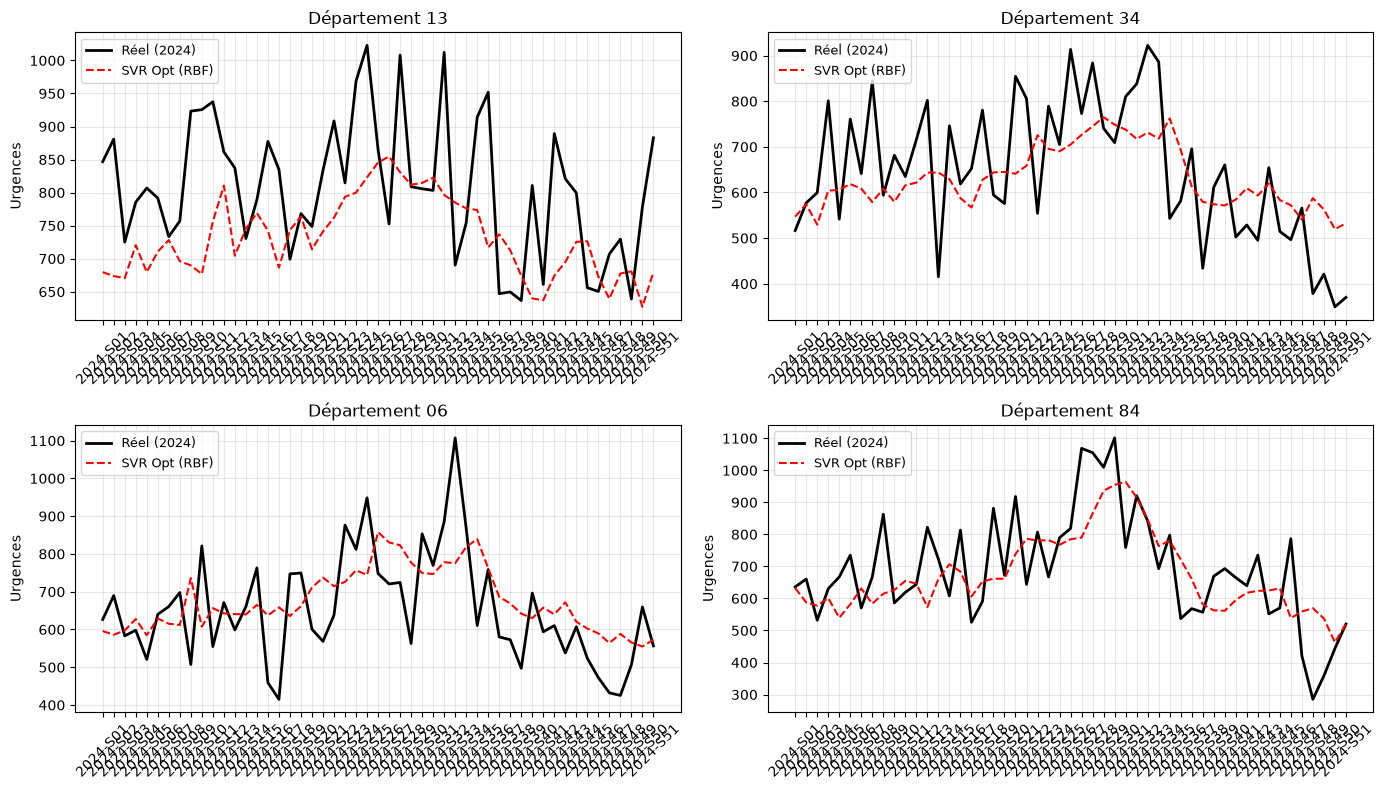

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# Ajout des prédictions SVR dans une copie du DataFrame de test
df_test_viz = df_test.copy()
df_test_viz['pred_svr'] = y_pred_test_opt

# Sélection des départements d'intérêt
depts_cibles = ['13', '34', '06', '84']

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=False)
axes = axes.flatten()

for i, dept in enumerate(depts_cibles):
  ax = axes[i]
  sub_df = df_test_viz[df_test_viz['code_dept'] == dept]

  ax.plot(
      sub_df['date_semaine'],
      sub_df['target_futur'],
      label='Réel (2024)',
      color='black',
      linewidth=2,
  )
  ax.plot(
      sub_df['date_semaine'],
      sub_df['pred_svr'],
      label='SVR Opt (RBF)',
      color='red',
      linestyle='--',
      linewidth=1.5,
  )

  ax.set_title(f'Département {dept}')
  ax.set_ylabel('Urgences')
  ax.legend(loc='upper left', fontsize=9)
  ax.grid(True, alpha=0.3)
  ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Étape 8 : Analyse de l'importance des variables

--- Top 10 des variables les plus importantes (SVR RBF) ---
                                      feature  importance_mean  importance_std
56                           moyenne_passe_2w         0.143518        0.002109
19                         temperature_kelvin         0.065171        0.000177
53                                semaine_cos         0.038896        0.000355
55                       lag_2_semaines_avant         0.028629        0.001240
37                                 pct_urbain         0.023767        0.003078
46                       densite_generalistes         0.019624        0.000435
34   prev_calc_Maladie_Respi_Chronique_0-14_9         0.018200        0.000603
11                                 NO3 in PM1         0.005725        0.000239
35  prev_calc_Maladie_Respi_Chronique_15-64_9         0.005521        0.000714
50                              densite_kines         0.004984        0.000417


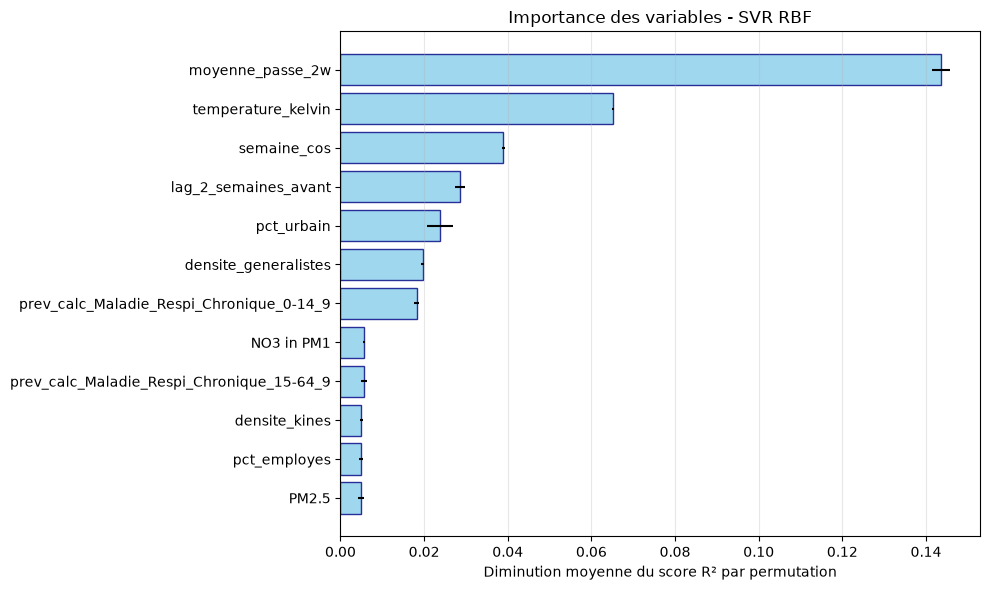

In [11]:
from sklearn.inspection import permutation_importance

# Calcul de la permutation importance sur le jeu de validation (2023)
result = permutation_importance(
    best_model, X_val_svr, y_val, n_repeats=3, random_state=42, n_jobs=-1
)

# Récupération des noms de features après le ColumnTransformer (numériques + encodage One-Hot des départements)
cat_encoder = preprocessor_svr.named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(cat_cols).tolist()
all_feature_names = num_cols + encoded_cat_cols

# Création d'un DataFrame récapitulatif trié
importance_df = pd.DataFrame({
    'feature': all_feature_names,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std,
}).sort_values('importance_mean', ascending=False)

print('--- Top 10 des variables les plus importantes (SVR RBF) ---')
print(importance_df.head(10))

# Visualisation graphique
plt.figure(figsize=(10, 6))
top_features = importance_df.head(12).iloc[::-1]  # Inverser pour l'affichage horizontal

plt.barh(
    top_features['feature'],
    top_features['importance_mean'],
    xerr=top_features['importance_std'],
    color='skyblue',
    edgecolor='navy',
    alpha=0.8,
)
plt.xlabel('Diminution moyenne du score R² par permutation')
plt.title(
    'Importance des variables - SVR RBF'
)
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

  0%|          | 0/50 [00:00<?, ?it/s]

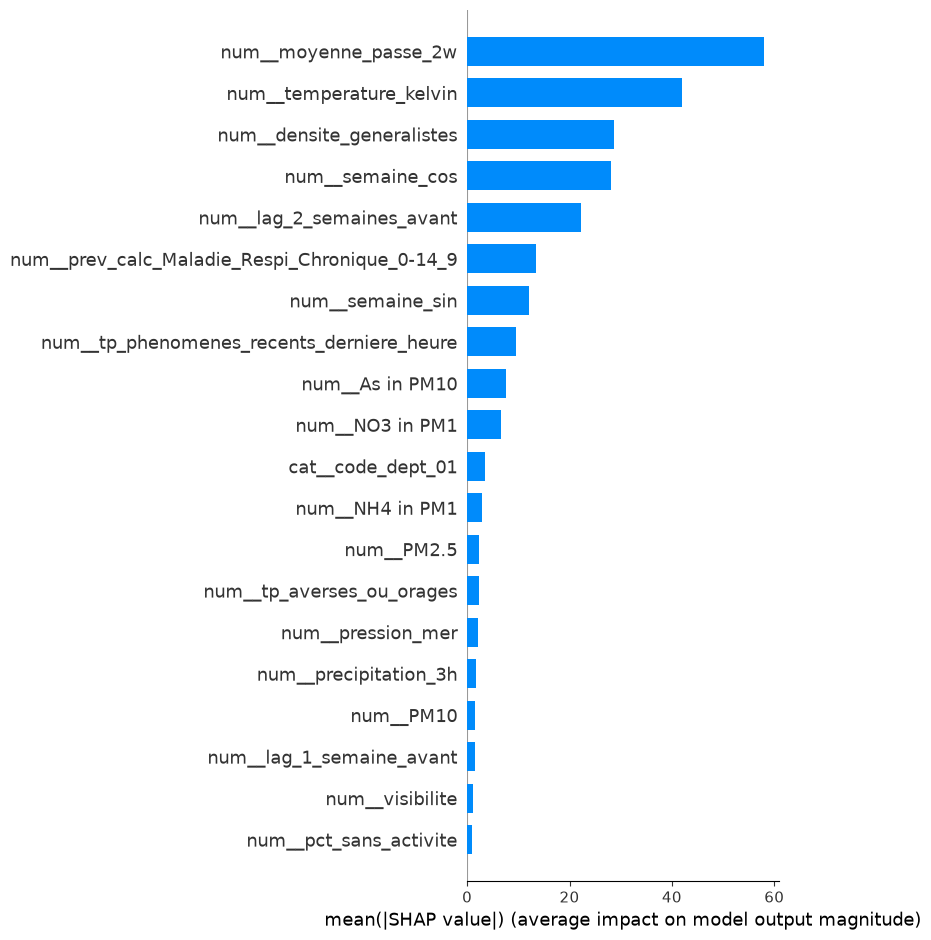

AssertionError: Feature and SHAP matrices must have the same number of rows!

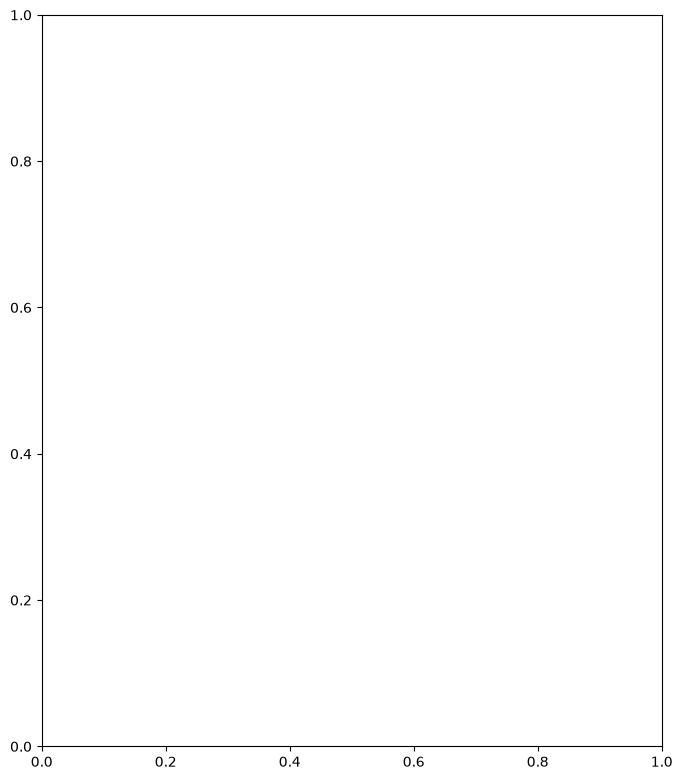

In [12]:
import shap

noms_colonnes = preprocessor_svr.get_feature_names_out()
X_test_svr_df = pd.DataFrame(X_test_svr, columns=noms_colonnes)
X_train_svr_df = pd.DataFrame(X_train_svr, columns=noms_colonnes)

X_train_summary = shap.kmeans(X_train_svr_df, 10)

explainer = shap.KernelExplainer(best_model.predict, X_train_summary)

X_test_sample = X_test_svr_df.head(50) 
shap_values = explainer(X_test_sample)

# Importance globale des facteurs de risque
plt.figure()
shap.summary_plot(shap_values, X_test_svr_df, plot_type="bar")

# Graphique d'impact (Visualiser si une valeur haute augmente ou baisse le risque)
plt.figure()
shap.summary_plot(shap_values, X_test_svr_df)